# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max"]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?


### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [2]:
# --- TODO: find the implausible rows ---
suspect = data.query("body_fat_pct <= 0 or height_in < 50 or (body_fat_pct <= 0 and height_in < 50)")

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect

,case,body_fat_pct,density,age,weight_lb,height_in,bmi,neck,chest,abdomen,hip,thigh,knee,ankle,biceps,forearm,wrist
41,42,32.9,1.0250,44,205.0,29.5,29.9,36.6,106.0,104.3,115.5,70.6,42.5,23.7,33.6,28.7,17.4
181,182,0.0,1.1089,40,118.5,68.0,18.1,33.8,79.3,69.4,85.0,47.2,33.5,20.2,27.7,24.6,16.5


In [3]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
# For a row you correct, change the value; for a row you remove, drop it; for a row you keep, do nothing.
clean = data.copy()

heights = suspect.loc[suspect["height_in"] < 50]
calc_height = np.sqrt(heights["weight_lb"] * 703 / heights["bmi"])

clean.loc[heights.index, "height_in"] = calc_height

for idx, height in calc_height.items():
    case = int(heights.loc[idx, "case"])
    print(f"Calculated height for case {case}: {height:.2f} inches")

false_bfp = suspect.loc[suspect["body_fat_pct"] <= 0]
calc_bfp = 495 / false_bfp["density"] - 450

for idx, body_fat in calc_bfp.items():
    case = int(false_bfp.loc[idx, "case"])
    print(f"Calculated body fat for case {case}: {body_fat:.2f}%")

clean = clean.drop(index=false_bfp.index)

assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

Calculated height for case 42: 69.43 inches
Calculated body fat for case 182: -3.61%
251 men remain after your decisions (1 removed)


**Answer 2.1** — For each row you flagged: what is wrong, what you did, and why. *(Replace this text.)*

For case 42, I calculated the missing height based on BMI and weight. Given its realistic outcome, the row was kept in the dataset, and the case's height was corrected to the calculated value.

For case 182, I calculated the missing body fat percentage from the case's recorded density. However, the resultant number was negative, making the case invalid. The row was thereby removed.

### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [4]:
from sklearn.linear_model import LinearRegression

leaky_column = "density"          # TODO: the name of the column

y = clean[target]

X_with = clean[measurements + [leaky_column]]
model_with = LinearRegression().fit(X_with, y)

X_without = clean[measurements]
model_without = LinearRegression().fit(X_without, y)

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---
r2_with    = model_with.score(X_with, y)            # R^2 on the data used for fitting, with the leaky column
r2_without = model_without.score(X_without, y)            # ... without it

assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** — Which column leaks, why (cite the formula), and why a model that used it would fail in a clinic.

Density leaks, as the data included in that column is calculated by Siri's formula based on the taken measurements. However, the model is trying to predict density from the clinical measurements. Therefore, including calculated density would bias the model. Additionally, measuring density requires underwater weighting, which is not accessable in clinics.

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [5]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=42)

assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.1%, standard deviation 8.3%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 7.83 percentage points
least squares:  training RMSE 3.97  R^2 0.772   |   validation RMSE 4.32  R^2 0.694
Intercept: -106.4298 percentage points
  feature  weight                       units  correlation_with_body_fat  opposite_sign
      age  0.0091    percentage points / year                     0.2473          False
weight_lb -0.3321   percentage points / pound                     0.6420           True
height_in  0.8902    percentage points / inch                     0.0589          False
      bmi  1.0709 percentage points / (kg/m²)                     0.7190          False
     neck -0.2981      percentage points / cm                     0.5334           True
    chest  0.0665      percentage points / cm                     0.7337          False
  abdomen  1.0332      percentage points / cm                     0.8184          False
      hip -0.2959      percentage points / cm                     0.6063           True
    thigh  0.3874 

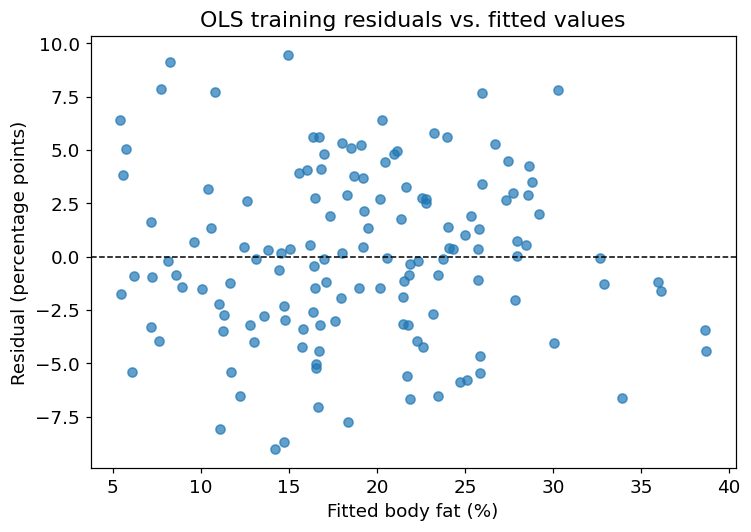


Training feature correlation matrix:
            age  weight_lb  height_in   bmi  neck  chest  abdomen   hip  thigh  knee  ankle  biceps  forearm  wrist
age        1.00      -0.03      -0.22  0.08  0.10   0.15     0.19 -0.07  -0.20  0.05  -0.17   -0.02    -0.04   0.18
weight_lb -0.03       1.00       0.49  0.91  0.84   0.89     0.91  0.94   0.88  0.85   0.64    0.79     0.62   0.73
height_in -0.22       0.49       1.00  0.08  0.30   0.23     0.25  0.40   0.31  0.47   0.42    0.32     0.33   0.38
bmi        0.08       0.91       0.08  1.00  0.80   0.91     0.92  0.88   0.85  0.74   0.53    0.75     0.56   0.65
neck       0.10       0.84       0.30  0.80  1.00   0.79     0.78  0.75   0.71  0.67   0.51    0.71     0.64   0.75
chest      0.15       0.89       0.23  0.91  0.79   1.00     0.92  0.80   0.73  0.71   0.50    0.72     0.58   0.66
abdomen    0.19       0.91       0.25  0.92  0.78   0.92     1.00  0.87   0.79  0.77   0.49    0.70     0.52   0.65
hip       -0.07       0.94       0

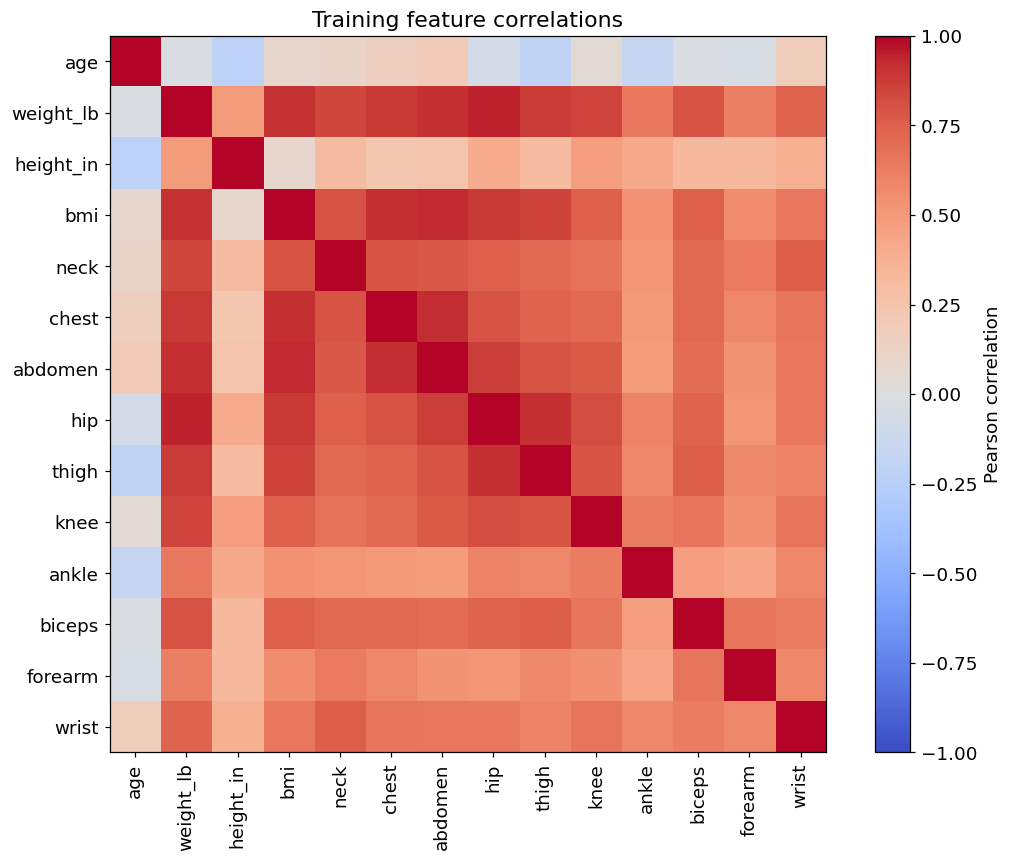

In [6]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

# --- TODO: fit least squares on all 14 measurements ---
ols            = LinearRegression().fit(X_train, y_train)          # the fitted model, or the weight vector from the normal equations
pred_train_ols = ols.predict(X_train)
pred_val_ols   = ols.predict(X_val)

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- TODO: print each weight with its units; plot residuals against fitted values; show the correlations --

units = {
    "age": "percentage points / year",
    "weight_lb": "percentage points / pound",
    "height_in": "percentage points / inch",
    "bmi": "percentage points / (kg/m²)",
    **{name: "percentage points / cm" for name in circumferences}
}

train_df = pd.DataFrame(X_train, columns=measurements)
target_corr = train_df.apply(lambda feature: np.corrcoef(feature, y_train)[0, 1])

weights = pd.DataFrame({
    "feature": measurements,
    "weight": ols.coef_,
    "units": [units[name] for name in measurements],
    "correlation_with_body_fat": target_corr.to_numpy()
})
weights["opposite_sign"] = (weights["weight"] * weights["correlation_with_body_fat"] < 0)

print(f"Intercept: {ols.intercept_:.4f} percentage points")
print(weights.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

residuals = y_train - pred_train_ols

#Plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pred_train_ols, residuals, alpha=0.7)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Fitted body fat (%)", ylabel="Residual (percentage points)", title="OLS training residuals vs. fitted values")
plt.tight_layout()
plt.show()

corr = train_df.corr()
print("\nTraining feature correlation matrix:")
print(corr.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(measurements)))
ax.set_yticks(range(len(measurements)))
ax.set_xticklabels(measurements, rotation=90)
ax.set_yticklabels(measurements)
ax.set_title("Training feature correlations")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

**Answer 4** — Which weights have a sign opposite to their feature's correlation with body fat, and why.

The weights for weight, neck, hip, ankle, and wrist are negative even though each feature is positively correlated with body fat. Correlation measures each feature's individual association with body fat, whereas a regression coefficient describes its association holding all other predictors fixed.

The correlation matrix shows multicollinearity, including weight-hip, with r=0.94; weight-abdomen, with r=0.91; and chest-abdomen, with r=0.92. These measurements contain overlapping information, so their coefficients only represent conditional adjustments after accounting for the other measurements, which can reverse their signs and make them less stable. Ultimately, a negative weight coefficient does not mean that gaining weight or other such associations causes body fat to decrease.

---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 0.01    validation RMSE there: 4.32    (least squares: 4.32)


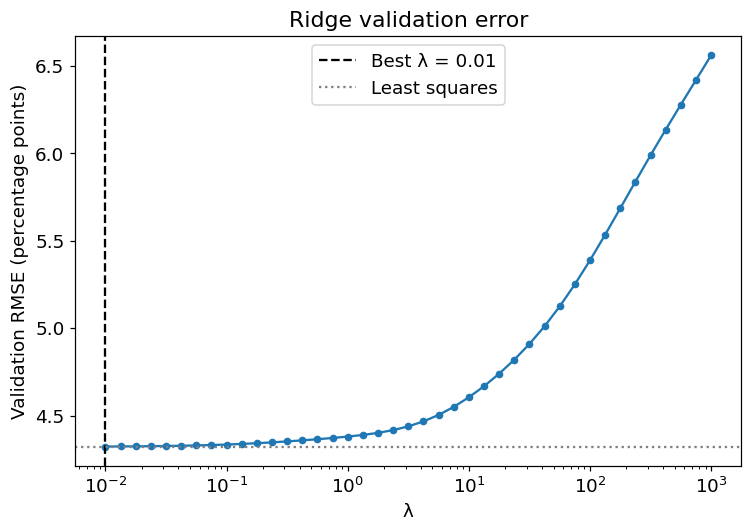

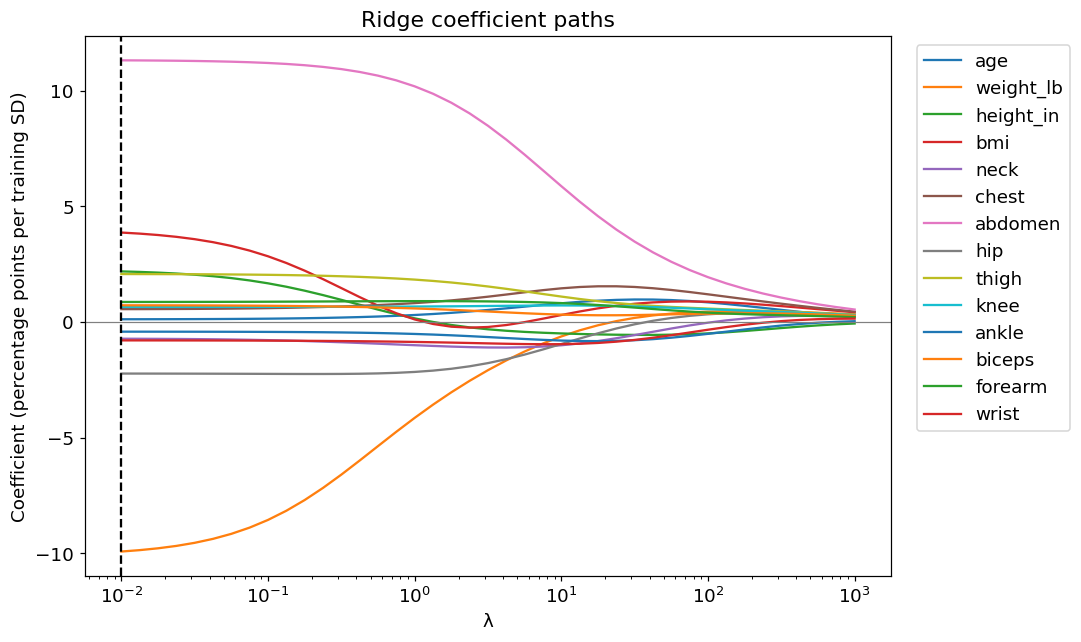

In [7]:
from sklearn.linear_model import Ridge

mu, sd         = X_train.mean(axis=0), X_train.std(axis=0)            # TODO: training-set mean and standard deviation of each measurement, shape (14,)
Z_train, Z_val = (X_train - mu) / sd, (X_val - mu) / sd            # TODO: standardised training and validation features

lambdas = np.logspace(-2, 3, 41)
# --- TODO: fit Ridge for every lambda; collect the validation RMSE and the weight vectors ---
val_rmse = np.empty(len(lambdas))
weights = np.empty((len(lambdas), len(measurements)))

for i, lam in enumerate(lambdas):
    model = Ridge(alpha=lam).fit(Z_train, y_train)
    val_rmse[i] = rmse(y_val, model.predict(Z_val))
    weights[i] = model.coef_

best_idx = np.argmin(val_rmse)
best_lambda = lambdas[best_idx]


assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# --- TODO: the two plots ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogx(lambdas, val_rmse, marker="o", markersize=4)
ax.axvline(best_lambda, color="black", linestyle="--", label=f"Best λ = {best_lambda:.3g}")
ax.axhline(rmse(y_val, pred_val_ols), color="gray", linestyle=":", label="Least squares")
ax.set(xlabel="λ", ylabel="Validation RMSE (percentage points)", title="Ridge validation error")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for j, name in enumerate(measurements):
    ax.semilogx(lambdas, weights[:, j], label=name)
ax.axvline(best_lambda, color="black", linestyle="--")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel="λ", ylabel="Coefficient (percentage points per training SD)", title="Ridge coefficient paths")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Answer 5** — Which $\lambda$ you chose and how; which weights the penalty shrinks first and why.

I chose lambda=0.01 because it lead to the lowest validation RMSE, which was approximately 4.32 percentage points. This was the smallest penalty tested and performed essentially the same as ordinary least squares.

The weight, BMI, and height coefficients contain overlapping information, so OLS can assign them large, compensating coefficients and shrinking the weights first. Ridge reduces these unstable contributions by penalising their squared magnitudes. The abdomen coefficient remains large for longer, which aligns with its typical predictive association with body fat.

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [8]:
# --- TODO: choose up to three measurements and fit least squares on them ---
chosen = ["abdomen", "wrist"]               # a list of 1 to 3 column names from `measurements`
chosen_idx = [measurements.index(name) for name in chosen]
small          = LinearRegression().fit(X_train[:, chosen_idx], y_train)                  # the fitted model
pred_val_small = small.predict(X_val[:, chosen_idx])

assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")

['abdomen', 'wrist']: validation RMSE 4.46   (full least squares 4.32, ridge 4.32, mean 7.83)


**Answer 6** — Your choice of measurements and the evidence for it.

I chose abdomen and wrist circumference. Abdomen had the strongest correlation with body fat at r=0.8184, and it was shown to have a large coefficient across the majority of the ridge path. Wrist was less correlated with abdomen than chest. BMI, or weight, making it a less redundant addition. Its negative coefficient in the full model and, simultaniously, positive individual correlation with body fat, means it is more likely to remain useful after accounting for other measurements.

---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

               model  test RMSE  test R^2
Development-set mean      8.533    -0.000
OLS, 14 measurements      5.014     0.655
       Ridge, λ=0.01      5.009     0.655
 OLS, abdomen, wrist      4.628     0.706


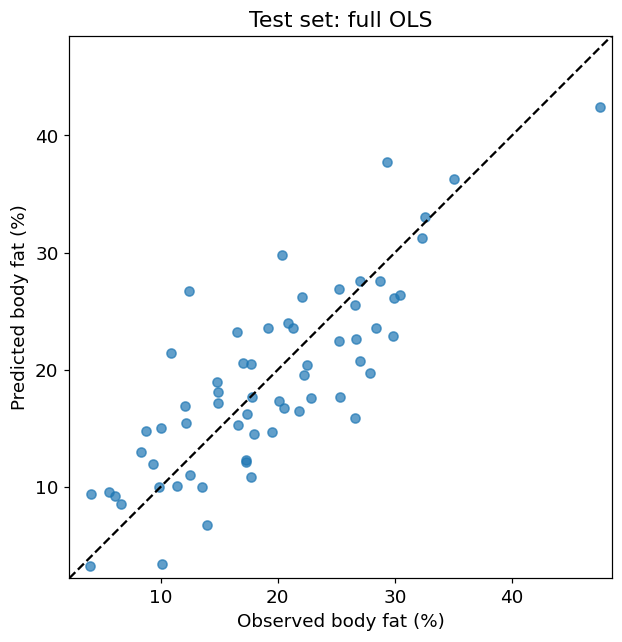

In [9]:
# --- TODO: refit each model on the development set and evaluate on the test set ---
ols_dev = LinearRegression().fit(X_dev, y_dev)
mu_dev, sd_dev = X_dev.mean(axis=0), X_dev.std(axis=0)
ridge_dev = Ridge(alpha=best_lambda).fit((X_dev - mu_dev) / sd_dev, y_dev)
idx = [measurements.index(c) for c in chosen]
small_dev = LinearRegression().fit(X_dev[:, idx], y_dev)

pred_mean = np.full_like(y_test, y_dev.mean(), dtype=float)
pred_ols = ols_dev.predict(X_test)
pred_ridge = ridge_dev.predict((X_test - mu_dev) / sd_dev)
pred_small = small_dev.predict(X_test[:, idx])

results = pd.DataFrame([[name, rmse(y_test, pred), r_squared(y_test, pred)]  # a DataFrame with the columns ["model", "test RMSE", "test R^2"] and four rows
    for name, pred in [
        ("Development-set mean", pred_mean),
        ("OLS, 14 measurements", pred_ols),
        (f"Ridge, λ={best_lambda:.3g}", pred_ridge),
        (f"OLS, {', '.join(chosen)}", pred_small)]],
    columns=["model", "test RMSE", "test R^2"])


assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- TODO: predicted against observed on the test set, with the diagonal ---

limits = [min(y_test.min(), pred_ols.min()) - 1, max(y_test.max(), pred_ols.max()) + 1]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_ols, alpha=0.7)
plt.plot(limits, limits, "k--")
plt.xlim(limits)
plt.ylim(limits)
plt.gca().set_aspect("equal")
plt.xlabel("Observed body fat (%)")
plt.ylabel("Predicted body fat (%)")
plt.title("Test set: full OLS")
plt.tight_layout()
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

### Report

**1. The task.**

Each row of (X) contains one man's age, weight, height, BMI, and ten body circumferences. The target (y) is body fat percentage estimated from underwater-weighing density. The dataset is composed of 252 men measured at Brigham Young University.

**2. Data decisions.**

Case 42's height was corrected to about 69.43 inches by calculating an estimate from his recorded weight and the BMI, since his original height data was improbable. Case 182 was removed because its recorded body fat was zero, and attempts to correct for it with density implied negative body fat. Finally, density was excluded because as it would have created target leakage.

**3. Results.**

model: (test RMSE,  test R^2)

Development-set mean:      8.533,    -0.000

* Shows that predicting one constant doesn't provide useful explanatory power.

OLS, 14 measurements:      5.014,     0.655

* Shows that the full OLS accounts for approximately 66% of test variation.

Ridge, λ=0.01:      5.009,     0.655

* Shows that Ridge performs almost identically to OLS.

OLS, abdomen, wrist:      4.628,     0.706

* Shows that the two-measurement model had the lowest test error.


**4. Two weights.**

In the full model's training fit, each additional centimeter of abdomen circumference predicts 1.0332 percentage points more body fat, when the other predictors are fixed. Each additional centimetre of wrist circumference predicts 0.8478 points less. Therefore, wrist's positive marginal correlation but negative coefficient can likely be attributed to adjustment for correlated measurements, not a legitimate causal effect.

**5. Limitations.**

The dataset does not account for women or children, and clinical errors in measurement could affect the coefficients. Additionally, multicollinearity has the potential to amplify their instability.

**6. Recommendation.**

Abdomen and wrist have the potential to serve as a two-measurement method for predicting BMI, given the test RMSE of about 4.63 percentage points. However, more testing is likely necessary to conclude these factors as inherently related, especially among broader demographics.

---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement** — In some cases, I utilized ChatGPT to help me recall coding syntax that I had previously forgotten. I also employed ChatGPT to elaborate on concepts that I had caused me confusion, to further my understanding of the theory behind these calculations and their correlated results.

### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.